# SC3000 Lab 1: Teaching NanoGPT to do Math

### Members and Contributions:
- Claire Boon Wan Ni: Task 1, Task 2
- Xie Xiao Mei: Task 3, Task 4

Task 4 (explanation and analysis) is written throughout the notebook in the text cells for each task.

#### How to run:
start Jupyter from inside the `dpo/` folder and run all cells from top to bottom (about 2 hours on an Apple M-series GPU).

### Step 1: Install necessary packages

In [1]:
!pip install matplotlib
!pip install torch numpy transformers datasets tiktoken wandb tqdm

### Step 2: Package imports and configuration

In [ ]:
import sys
import os
sys.path.append(os.path.abspath("..")) 
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import pickle
from model import GPT, GPTConfig
import random
from tqdm import tqdm
import time
import json
import matplotlib.pyplot as plt
# Configuration
beta = 0.5
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print("Using device:", device)
base_lr = 1e-3
epochs = 15
batch_size = 64
max_length =64
num_samples = 1
max_new_tokens = 200
temperature = 0.8
top_k = 200
# tokenizer
with open("../sft/meta.pkl", "rb") as f:
    meta = pickle.load(f)
stoi, itos = meta["stoi"], meta["itos"]
def encode(s): return [stoi[c] for c in s]
def decode(l): return ''.join([itos[i] for i in l])
# dropout turned off for the fine-tuning we do in step 7
dropout = 0.0
import math

Using device: mps


### Step 3: Define helper functions

In [3]:
def compute_logprob(input_ids):
    inputs = input_ids[:, :-1]
    targets = input_ids[:, 1:]
    logits, _ = gpt(inputs, full_seq=True)
    B, T, V = logits.size()
    logits_flat = logits.reshape(-1, V)
    targets_flat = targets.reshape(-1)
    loss = F.cross_entropy(logits_flat, targets_flat, ignore_index=0, reduction='none')
    loss = loss.reshape(B, T)
    attention_mask = (targets != 0).float()
    loss = (loss * attention_mask).sum(dim=1) / attention_mask.sum(dim=1)
    return -loss 

def pad_or_truncate(seq, max_length):
    return seq[-max_length:] if len(seq) > max_length else seq + [0] * (max_length - len(seq))

def get_batches(lines, batch_size):
    random.shuffle(lines)
    #for l in lines:
    #    print(l[1])
    for i in range(0, len(lines), batch_size):
        batch = lines[i:i+batch_size]
        if len(batch) < batch_size:
            continue
        neg_inputs = [pad_or_truncate(encode(p['negative'] + '\n\n\n\n'), max_length) for p in batch]
        pos_inputs = [pad_or_truncate(encode(p['positive'] + '\n\n\n\n'), max_length) for p in batch]
        neg_tensor = torch.tensor(neg_inputs, dtype=torch.long, device=device)
        pos_tensor = torch.tensor(pos_inputs, dtype=torch.long, device=device)
        yield neg_tensor, pos_tensor

### Step 4: Load the pretrained NanoGPT model

In [ ]:
ckpt = torch.load("../sft/gpt.pt", map_location=device)
model_args = dict(ckpt['model_args'])
# turn off dropout for fine-tuning
model_args['dropout'] = dropout
gptconf = GPTConfig(**model_args)
gpt = GPT(gptconf)
state_dict = ckpt['model']
unwanted_prefix = '_orig_mod.'
for k in list(state_dict.keys()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
gpt.to(device).train()

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(74, 348)
    (wpe): Embedding(256, 348)
    (drop): Dropout(p=0.0, inplace=False)
    (h): ModuleList(
      (0-5): 6 x Block(
        (ln_1): LayerNorm()
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=348, out_features=1044, bias=False)
          (c_proj): Linear(in_features=348, out_features=348, bias=False)
          (attn_dropout): Dropout(p=0.0, inplace=False)
          (resid_dropout): Dropout(p=0.0, inplace=False)
        )
        (ln_2): LayerNorm()
        (mlp): MLP(
          (c_fc): Linear(in_features=348, out_features=1392, bias=False)
          (gelu): GELU(approximate='none')
          (c_proj): Linear(in_features=1392, out_features=348, bias=False)
          (dropout): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm()
  )
  (lm_head): Linear(in_features=348, out_features=74, bias=False)
)

## __Task 1: Building positive-negative data pairs__
Each training example requires 2 contrasting responses to the same question: 
1. a positive reply, which is the correct answer with its working
2. a negative reply, which is what we don't want the model to say. 

Our DPO then teaches the model to prefer the positive one.

### __Our Approach__:

##### __1. Choosing the range to train our model__:
 Since the NanoGPT is a relatively small model, we first conditioned every number used in our questions and answers to be between 0 and 100 for more manageable arithmetics with just 3 or fewer digits. With the controlled range, we were able to generate deterministically every possible question, totalling at 33917. Hence, instead of picking random numbers, which may repeat questions and skip others, the first cell uses two loops to go through every pairwise combination of numbers between 0 to 100. Then, it will only keep a question if all of its numbers and answers stay within the range. Referencing lecture 6's Empirical Risk Minimization, we know that a model learns by lowering its average loss on the training data. More importantly, it only works well when the training data comes from the same distribution as the test data, as seen by the equation:

$P_{tr}(x,y) = P_{ts}(x,y)$
 
 As our training set covers every possible equation within the set range, the model gets to practice on the exact type of questions it will be tested on.

##### __2. Question Types__:
We created __nine question types__ to match the test sets as follows:
1. __Addition__: "a+b=?"
2. __Subtraction__: "a-b=?"
3. __Multiplication__: "a*b=?"
4. __Division__: "a/b=?"
5. __Algebraic addition__: "x+a=b,x=?" and "a+x=b,x=?"
6. __Algebraic subtraction (x first)__: "x-a=b,x=?"
7. __Algebraic subtraction (x second)__: "a-x=b,x=?"
8. __Algebraic multiplication__: "x*a=b,x=?" and "a*x=b,x=?"
9. __Algebraic division__: "x/a=b,x=?"

Example references:
{"72/4=?", "x+55=95,x=?", "55+x=95,x=?", "x-18=21,x=?", "72-x=34,x=?", "11*x=44,x=?" and "x/10=6,x=?"}

##### __3. Model's Responses__:
The positive replies will use the same wording as the sample file, for example __"72/4=?"__ will receive the response __"The answer is 18 because 72/4 equals 18"__. Furthermore, the working for equations demonstrates how to reverse the question to calculate x. For example __"x+55=95,x=?"__ will receive the response __"The answer is 40 because 95-55 equals to 40."__. To ensure every division returns a whole number, instead of dividing two random numbers, we picked the answer first and multiplied it out to build the question. We also left out anything that would subtract below 0 or divide by 0.

For the negatives, the second cell asks the pretrained NanoGPT 1000 of our questions and saves its responses. As the output shows, it refused every time, mostly with "Sorry, I don't know." and sometimes with variations like "Sory, I don't know." Since it nearly always says the same thing, the third cell uses " Sorry, I don't know." as the negative for the rest of the pairs. Asking the model all 100,000 questions would have taken around 3 hours just to get the same reply back, so this saved us a lot of time without changing the data. We couldn't use the sample file's "Sorry, I do not know!" because the model's codebook (`meta.pkl`) has no `!` character, so `encode()` crashes on it.

Initially, we considered using ChatGPT to write the positive replies as the guideline suggests, but decided to utilise deterministic logic to calculate them in Python instead. While ChatGPT, an AI, has the tendency to hallucinate values and calculations, deterministic python logic will never make arithmetic mistakes as long as we write the correct rules. Considering the cost of even a few wrong answers from ChatGPT potentially teaching the model the wrong logic, we went with the safer deterministic route. Moreover, it also meant that all 100000 replies come out in exactly the same format within seconds.

##### __4. Training and Testing Sets__:
We intentionally withheld 180 questions, 20 from each question type, from the set of training questions. This gave us a fair way to check later whether the model had actually learned the maths, rather than just remembering questions it had already seen. 

##### __5. Verification Layers__:
The third cell then builds the 100000 pairs by going through the question list about three times, and checks every pair before saving. We added these checks after reading through the template code and noticing three things that could break training without any error message:

1. Every character has to exist in the codebook. 
2. Every reply has to fit in 64 characters as `get_batches` adds four newlines to each reply and `pad_or_truncate` keeps only the last 64 characters, so a reply that was too long would lose the question at the front.
3. Each positive response can only have one full stop, because `gpt.generate` stops writing at the first one.

##### __6. Output__
There are 33917 questions in total, with the `x+a` type having the most questions since it includes both `x+a=b` and `a+x=b`, while multiplication and division have far fewer with only smaller numbers multiplying to 100 or less. All 100000 pairs passed the checks, and they contain 33737 different questions. That is every question except the 180 we held out, which confirms none of our test questions ended up in the training data. The longest positive is 58 characters, so everything fits within the limit.

#### Task 1a: Listing every question and holding out 180 for testing

In [ ]:
# Ensure questions and held-out set are the same every run
random.seed(42)
torch.manual_seed(42)
# Maximum number size
N = 100

questions = {k: [] for k in ["add", "sub", "mul", "div", "x+a", "x-a", "a-x", "x*a", "x/a"]}

# Listing question types and how model should respond
for a in range(N + 1):
    for b in range(N + 1):
        if a + b <= N:
            questions["add"].append((f"{a}+{b}=?", a + b, f"{a}+{b} equals {a + b}."))
            x, c = a, b
            questions["x+a"].append((f"x+{c}={x + c},x=?", x, f"{x + c}-{c} equals to {x}."))
            questions["x+a"].append((f"{c}+x={x + c},x=?", x, f"{x + c}-{c} equals to {x}."))
        if b <= a:
            questions["sub"].append((f"{a}-{b}=?", a - b, f"{a}-{b} equals {a - b}."))
            questions["x-a"].append((f"x-{b}={a - b},x=?", a, f"{a - b}+{b} equals to {a}."))
            questions["a-x"].append((f"{a}-x={a - b},x=?", b, f"{a}-{a - b} equals to {b}."))
        if a * b <= N:
            questions["mul"].append((f"{a}*{b}=?", a * b, f"{a}*{b} equals {a * b}."))
            if b >= 1:
                questions["div"].append((f"{a * b}/{b}=?", a, f"{a * b}/{b} equals {a}."))
                questions["x*a"].append((f"x*{b}={a * b},x=?", a, f"{a * b}/{b} equals to {a}."))
                questions["x*a"].append((f"{b}*x={a * b},x=?", a, f"{a * b}/{b} equals to {a}."))
                questions["x/a"].append((f"x/{b}={a},x=?", a * b, f"{a}*{b} equals to {a * b}."))

for kind, qs in questions.items():
    print(f"{kind:4s}: {len(qs)} unique questions")
print("Total unique questions:", sum(len(qs) for qs in questions.values()))

# Withhold 180 questions, 20 from each question type, from the training set
heldout_set, heldout_q = [], set()
for kind, qs in questions.items():
    for q, ans, _ in random.sample(qs, 20):
        heldout_q.add(q)
        heldout_set.append((kind, q, ans))
print("Held-out questions:", len(heldout_set))

add : 5151 unique questions
sub : 5151 unique questions
mul : 683 unique questions
div : 582 unique questions
x+a : 10302 unique questions
x-a : 5151 unique questions
a-x : 5151 unique questions
x*a : 1164 unique questions
x/a : 582 unique questions
Total unique questions: 33917
Held-out questions: 180


#### Task 1b: Generate negatives with the pretrained NanoGPT

In [ ]:
# Number of negatives generated by the pretrained model
N_negative = 1000
gpt.eval()

# training questions
all_questions = [item for qs in questions.values() for item in qs if item[0] not in heldout_q]
real_negatives = []
with torch.no_grad():
    for q, ans, working in random.sample(all_questions, N_negative):
        x = torch.tensor(encode(q), dtype=torch.long, device=device)[None, ...]
        y, _ = gpt.generate(x, 40, temperature=temperature, top_k=top_k)
        neg = decode(y[0].tolist()).strip()
        real_negatives.append((q, ans, working, neg))
gpt.train()

print("Generated", len(real_negatives), "negatives with the pretrained NanoGPT, e.g.:")
for item in real_negatives[:5]:
    print("  ", item[3])

Generated 1000 negatives with the pretrained NanoGPT, e.g.:
   31+x=95,x=? Sorry, I don't know.
   x-23=70,x=? Sorry, I don't know.
   x-12=61,x=? Sorry, I don't know.
   59-x=13,x=? Sorry, I don't know.
   72-x=4,x=? Sorry, I don't know.


#### Task 1c: Build, verify and save each of the 100000 pairs

In [ ]:
# Most common negative response
Negative_text = " Sorry, I don't know."
TARGET = 100000

pairs = []
for q, ans, working, neg in real_negatives:
    pairs.append({"negative": neg, "positive": f"{q} The answer is {ans} because {working}"})

while len(pairs) < TARGET:
    random.shuffle(all_questions)
    for q, ans, working in all_questions:
        if len(pairs) >= TARGET:
            break
        pairs.append({"negative": q + Negative_text,
                      "positive": f"{q} The answer is {ans} because {working}"})
random.shuffle(pairs)

def valid(s):
    return all(ch in stoi for ch in s) and len(s) + 4 <= max_length

before = len(pairs)
pairs = [p for p in pairs if valid(p["negative"]) and valid(p["positive"])]
for p in pairs:
    assert p["positive"].count(".") == 1

print("Removed invalid pairs:", before - len(pairs))
print("Total pairs:", len(pairs))
print("Unique questions:", len(set(p["positive"].split(" ")[0] for p in pairs)))
print("Longest positive:", max(len(p["positive"]) for p in pairs))
for p in random.sample(pairs, 5):
    print(p)

with open("./pos_neg_pairs.json", "w") as f:
    json.dump(pairs, f, indent=0)
print("Saved to ./pos_neg_pairs.json")

Removed invalid pairs: 0
Total pairs: 100000
Unique questions: 33737
Longest positive: 58
{'negative': "88-79=? Sorry, I don't know.", 'positive': '88-79=? The answer is 9 because 88-79 equals 9.'}
{'negative': "67+27=? Sorry, I don't know.", 'positive': '67+27=? The answer is 94 because 67+27 equals 94.'}
{'negative': "43+x=92,x=? Sorry, I don't know.", 'positive': '43+x=92,x=? The answer is 49 because 92-43 equals to 49.'}
{'negative': "72-x=54,x=? Sorry, I don't know.", 'positive': '72-x=54,x=? The answer is 18 because 72-54 equals to 18.'}
{'negative': "x-8=65,x=? Sorry, I don't know.", 'positive': 'x-8=65,x=? The answer is 73 because 65+8 equals to 73.'}
Saved to ./pos_neg_pairs.json


## __Task 2: Fine-tuning NanoGPT with DPO__

### Step 5: Load Data
We loaded the pairs from `pos_neg_pairs.json` into `lines`, and chose to read the file back instead of reusing the list from Task 1, so the model trains on exactly the same file we submit. The output of 100000 pairs is what we expected, and the example pair matches the format built in Task 1. With a batch size of 64, this gives 1562 batches per epoch.

In [ ]:
# Loading the pairs built in Task 1
with open("./pos_neg_pairs.json", "r") as f:
    lines = json.load(f)

print("Number of pairs loaded:", len(lines))
print("Batches per epoch:", len(lines) // batch_size)
print("Example pair:")
print("  negative:", lines[0]["negative"])
print("  positive:", lines[0]["positive"])

Number of pairs loaded: 100000
Batches per epoch: 1562
Example pair:
  negative: 70+x=86,x=? Sorry, I don't know.
  positive: 70+x=86,x=? The answer is 16 because 86-70 equals to 16.


### Step 6: Build the optimizer and scheduler

We used the AdamW optimizer as recommended, with a small weight decay of 0.01. For the learning rate, we wrote a `get_lr` function based on the schedule in the nanoGPT repository's `train.py` (https://github.com/karpathy/nanoGPT). The learning rate starts near 0 and rises to 1e-3 over the first 300 steps, then slowly comes back down along a cosine curve to 1e-4 by the end. The slow start prevents the model from making big, unstable changes before it has adjusted to the new task. The gradual decrease allows it to take larger steps in the early stages when there is a lot to learn, and smaller steps near the end so it can refine its answers accordingly.

With 15 epochs comprising of1562 steps each, training runs with a total of 23430 steps. The printed values show the schedule working as planned: the learning rate starts at 3.3e-6, reaches 1e-3 after the warm-up, is at 5.6e-4 halfway through, and finishes at 1e-4. We explain in Step 7 why we ended up using 1e-3 and 15 epochs instead of the template's 1e-4 and 5.

In [ ]:
# recommend to use the AdamW optimizer 
optimizer = torch.optim.AdamW(gpt.parameters(), lr=base_lr, weight_decay=0.01)
steps_per_epoch = len(lines) // batch_size
num_training_steps = epochs * steps_per_epoch
warmup_steps = 300
min_lr = base_lr * 0.1

# learning rate schedule based on nanoGPT's train.py
def get_lr(it):
    if it < warmup_steps:
        return base_lr * (it + 1) / warmup_steps
    progress = (it - warmup_steps) / (num_training_steps - warmup_steps)
    return min_lr + 0.5 * (base_lr - min_lr) * (1 + math.cos(math.pi * progress))

print("Steps per epoch:", steps_per_epoch)
print("Total training steps:", num_training_steps)
print("lr at start, end of warm-up, middle, end:",
      [f"{get_lr(s):.2e}" for s in [0, warmup_steps, num_training_steps // 2, num_training_steps - 1]])

Steps per epoch: 1562
Total training steps: 23430
lr at start, end of warm-up, middle, end: ['3.33e-06', '1.00e-03', '5.59e-04', '1.00e-04']


### Step 7: Begin training

We used the loss equation suggested:

$$\text{loss} = -\log \sigma\left(\frac{\log p(\text{pos}) - \log p(\text{neg})}{\beta}\right) - 0.1 \log p(\text{pos})$$

The first part rewards the model for making the correct reply more likely than the refusal. This is similar to the policy gradient idea in Lecture 6, where good trajectories are made more likely and bad ones less likely, but DPO compares two replies instead of using a reward. The second part trains the model directly on the correct reply, the same way GPT is normally trained.

##### __Initial Run__: 
We first trained with the template's settings, using a learning rate of 1e-4 for 5 epochs. While the model quickly stopped refusing and answered in the right format, only 41.1% of its answers to our held-out questions were correct. Even with the questions it specifically trained on, the model got many questions wrong, suggesting that the problem was not because of a lack of data. Instead, the model simply was not learning enough during training. Looking at the gradient descent update from Lecture 6, $w_{i+1} = w_i - \rho \, \partial E / \partial w$, we realised our step size $\rho$ was too small for the model to pick up the arithmetic in 5 epochs. We also tried using wrong answers as negatives and making the second part of the loss stronger, but neither helped.

##### __Final Improved model__:
 We raised the learning rate to 1e-3, increased the epochs to 15, and added the learning rate schedule from Step 6. We also turned off dropout in Steps 2 and 4. Dropout is meant to stop a model from memorising its training data, but our data already covers every possible question, so it was only making it harder to learn exact digits. We added gradient clipping to stop any single update from being too large, and we now test the model on the held-out questions after every epoch, saving `dpo.pt` only when it does better than before.

These changes made a significant difference, with accuracy rising from 28.3% after the first epoch to 81.7% after the third. While it dipped slightly in the middle when the learning rate was still high, it gradually improved itself and reached 100% in epochs 14 and 15.

In [ ]:
total_steps = len(lines) // batch_size
loss_history = []
accuracy_history = []
best_accuracy = -1.0
global_step = 0
start = time.time()

# Percentage of the 180 held-out questions being answered correctly
def heldout_accuracy():
    gpt.eval()
    correct = 0
    with torch.no_grad():
        for kind, q, ans in heldout_set:
            x = torch.tensor(encode(q), dtype=torch.long, device=device)[None, ...]
            y, _ = gpt.generate(x, 60, temperature=temperature, top_k=1)
            output = decode(y[0].tolist())
            try:
                predicted = int(output.split("The answer is ")[1].split(" ")[0])
            except (IndexError, ValueError):
                predicted = None
            correct += (predicted == ans)
    gpt.train()
    return correct / len(heldout_set)

for epoch in range(epochs):
    pbar = tqdm(get_batches(lines, batch_size), total=total_steps)
    for step, (neg_tensor, pos_tensor) in enumerate(pbar):
        lr = get_lr(global_step)
        for group in optimizer.param_groups:
            group['lr'] = lr

        neg_logprob = compute_logprob(neg_tensor)
        pos_logprob = compute_logprob(pos_tensor)
        dpo_loss = -F.logsigmoid((pos_logprob - neg_logprob) / beta).mean()
        sft_loss = -pos_logprob.mean()
        loss = dpo_loss + 0.1 * sft_loss

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0)
        optimizer.step()

        loss_history.append(loss.item())
        global_step += 1
        pbar.set_description(f"Epoch {epoch + 1}/{epochs} | loss {loss.item():.4f} | lr {lr:.2e}")

    accuracy = heldout_accuracy()
    accuracy_history.append(accuracy)
    print(f"Epoch {epoch + 1}: held-out accuracy {accuracy:.1%}")

    if accuracy >= best_accuracy:
        best_accuracy = accuracy
        ckpt_path = f"./dpo.pt"
        torch.save({
            "model_state_dict": gpt.state_dict(),
            "model_args": model_args,
        }, ckpt_path)
        print(f"Saved checkpoint to {ckpt_path}")

print(f"Best held-out accuracy: {best_accuracy:.1%}. Training took {(time.time() - start) / 60:.1f} minutes")

Epoch 1/15 | loss 0.0227 | lr 9.93e-04: 100%|██████████| 1562/1562 [10:15<00:00,  2.54it/s]


Epoch 1: held-out accuracy 28.3%
Saved checkpoint to ./dpo.pt


Epoch 2/15 | loss 0.0193 | lr 9.67e-04: 100%|██████████| 1562/1562 [12:27<00:00,  2.09it/s]


Epoch 2: held-out accuracy 69.4%
Saved checkpoint to ./dpo.pt


Epoch 3/15 | loss 0.0172 | lr 9.23e-04: 100%|██████████| 1562/1562 [08:57<00:00,  2.91it/s]


...

Epoch 13: held-out accuracy 99.4%
Saved checkpoint to ./dpo.pt


Epoch 14/15 | loss 0.0163 | lr 1.10e-04: 100%|██████████| 1562/1562 [07:44<00:00,  3.36it/s]


Epoch 14: held-out accuracy 100.0%
Saved checkpoint to ./dpo.pt


Epoch 15/15 | loss 0.0164 | lr 1.00e-04: 100%|██████████| 1562/1562 [07:59<00:00,  3.25it/s]


Epoch 15: held-out accuracy 100.0%
Saved checkpoint to ./dpo.pt
Best held-out accuracy: 100.0%. Training took 126.8 minutes


### __Visualisation of Overall Progress__
In the graphs below, the loss flattens out early because it is averaged over every character, including the random digits in each question, so the accuracy graph gives a much clearer picture of the model's progress. The grey dashed line marks our first attempt (41.1%), which the final model passed by the second epoch.

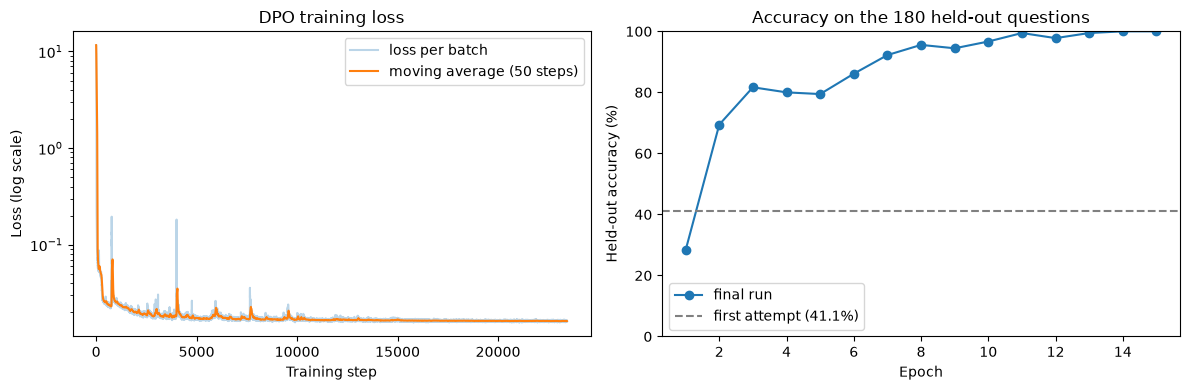

In [16]:
window = 50
smoothed = [sum(loss_history[max(0, i - window + 1):i + 1]) / len(loss_history[max(0, i - window + 1):i + 1])
            for i in range(len(loss_history))]

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
ax_loss.plot(loss_history, alpha=0.3, label="loss per batch")
ax_loss.plot(smoothed, label=f"moving average ({window} steps)")
ax_loss.set_yscale("log")
ax_loss.set_xlabel("Training step")
ax_loss.set_ylabel("Loss (log scale)")
ax_loss.set_title("DPO training loss")
ax_loss.legend()

ax_acc.plot(range(1, len(accuracy_history) + 1), [100 * a for a in accuracy_history], marker="o", label="final run")
ax_acc.set_ylim(0, 100)
ax_acc.set_xlabel("Epoch")
ax_acc.set_ylabel("Held-out accuracy (%)")
ax_acc.set_title("Accuracy on the 180 held-out questions")
ax_acc.axhline(41.1, color="grey", linestyle="--", label="first attempt (41.1%)")
ax_acc.legend()
plt.tight_layout()
plt.show()

## __Task 3: Testing the fine-tuned model__

### Step 8: Begin testing

The saved `dpo.pt` is loaded into a fresh model the same way the template does, but changed `.cuda()` to `.to(device)` because we trained on a Mac. To generate an answer, we encode the prompt, add an extra dimension because the model expects a batch, run `gpt.generate` and decode the result back into text. We also set `top_k` to 1, so the model always picks its most likely next character instead of sampling. Each question only has one right answer, so random sampling only adds a chance of mistakes. In our first attempt, this change alone raised held-out accuracy from 33% to 41%.

All 8 printed answers are correct, and the working is correct too. For the equations, the model writes the reverse operation as its working, for example "72-34" for "72-x=34". However, since our dataset includes every question from 0 to 100, most of these test questions were also in our training data, so we test the model on our held-out questions below.

In [ ]:
# Load the fine-tuned model
ckpt_path = "../dpo/dpo.pt"
checkpoint = torch.load(ckpt_path, map_location=device)
gptconf = GPTConfig(**checkpoint['model_args'])

# .to(device) instead of .cuda() so it also runs on CPU
gpt = GPT(gptconf).to(device)
try:
    state_dict = checkpoint['model']
except:
    state_dict = checkpoint['model_state_dict']
unwanted_prefix = '_orig_mod.'
for k,v in list(state_dict.items()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)

# Test
gpt.eval()

# Greedy decoding to pick the most likely next character
test_top_k = 1
test_set = ["17+19=?", "3*17=?", "72/4=?", "72-x=34,x=?", "x*11=44,x=?", "3*17=?", "72/4=?", "72-x=34,x=?"]
with torch.no_grad():
    for prompt in test_set: 
        prompt_ids = encode(prompt)
        x = torch.tensor(prompt_ids, dtype=torch.long, device=device)[None, ...]
        y, _ = gpt.generate(x, max_new_tokens, temperature=temperature, top_k=test_top_k)
        print(decode(y[0].tolist()))

17+19=? The answer is 36 because 17+19 equals 36.
3*17=? The answer is 51 because 3*17 equals 51.
72/4=? The answer is 18 because 72/4 equals 18.
72-x=34,x=? The answer is 38 because 72-34 equals to 38.
x*11=44,x=? The answer is 4 because 44/11 equals to 4.
3*17=? The answer is 51 because 3*17 equals 51.
72/4=? The answer is 18 because 72/4 equals 18.
72-x=34,x=? The answer is 38 because 72-34 equals to 38.


#### __Accuracy on the 180 held-out questions__
To check whether the model actually learned the maths, we test it on the 180 questions we held out in Task 1, which it never saw during training. The model got all 180 right, 20 out of 20 for every question type.

##### __Limitations__
Considering the fact that 180 questions is not a huge test, 100% may show that the model is very accurate but does not necessarily prove that it is perfect on every possible question. Furthermore, a held-out question hasn't been seen in that exact form, but a very similar one may have been used in the training set (for example "44+x=97,x=?" when "x+44=97,x=?" was held out). Finally, the original DPO paper also compares the model against a frozen copy of itself, while we used the template's simpler version of the loss.

In [ ]:
# Accuracy of the responses on the 180 withheld questions, counted per question type
correct_by_type = {}
with torch.no_grad():
    for kind, q, ans in heldout_set:
        x = torch.tensor(encode(q), dtype=torch.long, device=device)[None, ...]
        y, _ = gpt.generate(x, max_new_tokens, temperature=temperature, top_k=test_top_k)
        output = decode(y[0].tolist())
        try:
            predicted = int(output.split("The answer is ")[1].split(" ")[0])
        except (IndexError, ValueError):
            predicted = None
        correct_by_type.setdefault(kind, [0, 0])
        correct_by_type[kind][0] += (predicted == ans)
        correct_by_type[kind][1] += 1

total_correct = sum(c for c, n in correct_by_type.values())
print(f"Overall held-out accuracy: {total_correct}/{len(heldout_set)} = {total_correct / len(heldout_set):.1%}")
for kind, (c, n) in correct_by_type.items():
    print(f"  {kind:4s}: {c}/{n}")

Overall held-out accuracy: 180/180 = 100.0%
  add : 20/20
  sub : 20/20
  mul : 20/20
  div : 20/20
  x+a : 20/20
  x-a : 20/20
  a-x : 20/20
  x*a : 20/20
  x/a : 20/20


### __References__
- A. Karpathy, nanoGPT: https://github.com/karpathy/nanoGPT. `model.py` and `configurator.py` come from this repository and were not changed, and our learning rate schedule is based on its `train.py`.
- Course base code: https://github.com/zhouyuan888888/NanoGPT-Math (pretrained model, codebook, sample data and template notebook, including the helper functions and the suggested loss).
- R. Rafailov et al., "Direct Preference Optimization: Your Language Model is Secretly a Reward Model", NeurIPS 2023: https://arxiv.org/abs/2305.18290
- SC3000 Lecture 6: Empirical Risk Minimization, gradient descent, GPT and policy gradient.